# Security logging and monitoring for an AI service

**Module 18 — Security Logging, Monitoring and Incident Recovery**

Logs are evidence, not a debugging convenience. This notebook builds structured JSON logs with redaction,
chains them so tampering is detectable, turns them into rate metrics, and detects an anomaly with a simple,
explainable rule.

Synthetic traffic only: a mocked classifier returns fixed responses and no real user data is present.

## Learning objectives

1. Emit structured log records with a fixed schema and no personal data.
2. Redact sensitive fields before they reach disk.
3. Build a hash chain that makes silent deletion or edits detectable.
4. Compute security metrics from logs and detect a spike.
5. State what a log can and cannot prove.

## Background

Four properties make a log useful in an incident:

* **Structured** — fields, not prose, so it can be queried.
* **Attributable** — principal, action, resource, decision, request id.
* **Minimised** — no secrets, no personal data beyond what is required.
* **Tamper-evident** — appending is cheap; rewriting is detectable.

The last property is often skipped. A hash chain is not a defence against an attacker with write access to the
whole chain, but it makes local edits and deletions visible, which is usually enough to notice.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "matplotlib>=3.9"
```

Standard library plus NumPy and pandas. No log infrastructure is required; the log is a list of dicts.

In [1]:
import hashlib
import json
import re
from datetime import datetime, timedelta, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 71
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 160)
print("ready")

ready


**Expected output** — `ready`.

### Step 1 — Redact before writing

Redaction must happen at the logging boundary. If the raw value reaches a file, it is already in backups, log
shippers and alerts.

In [2]:
EMAIL = re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+")
CARD = re.compile(r"\b\d{13,16}\b")


def redact(text):
    text = EMAIL.sub("<redacted:email>", text)
    text = CARD.sub("<redacted:card>", text)
    return text


raw = "User jane.doe@example.org reported card 4111111111111111 on invoice 88123"
print(redact(raw))
assert "jane.doe" not in redact(raw) and "4111111111111111" not in redact(raw)

User <redacted:email> reported card <redacted:card> on invoice 88123


**Expected output** — the same sentence with `<redacted:email>` and `<redacted:card>`, and two assertions that
pass. Note the invoice number is kept: minimisation means removing what is unnecessary, not removing everything.

### Step 2 — A fixed schema, with a hash chain

Every record has the same fields plus `prev_hash` and `hash`. Changing any earlier record breaks every later
link.

In [3]:
SCHEMA_FIELDS = ["ts", "request_id", "principal", "action", "resource", "decision", "reason", "latency_ms"]


def make_record(index, principal, action, decision, reason="ok", latency_ms=None):
    ts = (datetime(2026, 3, 2, 9, 0, tzinfo=timezone.utc) + timedelta(seconds=index)).isoformat()
    return {
        "ts": ts,
        "request_id": f"req-{index:05d}",
        "principal": principal,
        "action": action,
        "resource": redact("doc:alpha:1"),
        "decision": decision,
        "reason": reason,
        "latency_ms": latency_ms if latency_ms is not None else int(rng.integers(30, 90)),
    }


def chain(records):
    prev = "0" * 64
    out = []
    for rec in records:
        payload = json.dumps({**rec, "prev_hash": prev}, sort_keys=True)
        digest = hashlib.sha256(payload.encode()).hexdigest()
        out.append({**rec, "prev_hash": prev, "hash": digest})
        prev = digest
    return out


base = [make_record(i, "alice" if i % 3 else "bob", "classify", "allow") for i in range(6)]
logged = chain(base)
print(json.dumps(logged[0], indent=2))

{
  "ts": "2026-03-02T09:00:00+00:00",
  "request_id": "req-00000",
  "principal": "bob",
  "action": "classify",
  "resource": "doc:alpha:1",
  "decision": "allow",
  "reason": "ok",
  "latency_ms": 87,
  "prev_hash": "0000000000000000000000000000000000000000000000000000000000000000",
  "hash": "1dd8bb4a989002486a4140a9aace860f56b27c679d8b05fa0ed3664e62fb2bad"
}


**Expected output** — one record with the eight schema fields plus two hash fields. The record is the unit an
investigator reads; the chain is the property that makes the collection trustworthy.

### Step 3 — Verify the chain, then tamper

Verification recomputes each link. Changing one decision from `allow` to `deny` must be detected at that record.

In [4]:
def verify_chain(records):
    prev = "0" * 64
    for i, rec in enumerate(records):
        payload = json.dumps({k: v for k, v in rec.items() if k != "hash"} | {"prev_hash": prev}, sort_keys=True)
        expected = hashlib.sha256(payload.encode()).hexdigest()
        if rec["hash"] != expected:
            return {"ok": False, "first_bad_index": i, "request_id": rec["request_id"]}
        prev = rec["hash"]
    return {"ok": True, "first_bad_index": None, "request_id": None}


print("intact:", verify_chain(logged))

tampered = [dict(r) for r in logged]
tampered[3]["decision"] = "deny"
print("tampered:", verify_chain(tampered))

removed = logged[:2] + logged[3:]
print("deleted row:", verify_chain(removed))

intact: {'ok': True, 'first_bad_index': None, 'request_id': None}
tampered: {'ok': False, 'first_bad_index': 3, 'request_id': 'req-00003'}
deleted row: {'ok': False, 'first_bad_index': 2, 'request_id': 'req-00003'}


**Expected output** — `intact: ok True`, then a failure at index 3 for the edited record, then a failure at index
2 for the deletion. Both tampering modes are detected; neither is *prevented*, which is why the log should be
shipped off-host as well.

### Step 4 — Metrics from logs

Three rates that matter for an AI service: refusals, authorisation denials, and payload flags. They are computed,
not guessed.

In [5]:
minutes = 60
records = []
for i in range(600):
    minute = i // 10
    principal = rng.choice(["alice", "bob", "carol"])
    decision = "deny" if rng.random() < 0.12 else "allow"
    reason = rng.choice(["role not permitted", "quota exhausted", "ok"]) if decision == "deny" else "ok"
    records.append({"minute": minute, "principal": principal, "decision": decision, "reason": reason})

traffic = pd.DataFrame(records)
per_minute = traffic.groupby("minute").agg(
    requests=("decision", "size"),
    denials=("decision", lambda s: int((s == "deny").sum())),
).reset_index()
per_minute["denial_rate"] = (per_minute.denials / per_minute.requests).round(3)
per_minute.head()

,minute,requests,denials,denial_rate
0,0,10,2,0.2
1,1,10,0,0.0
2,2,10,1,0.1
3,3,10,3,0.3
4,4,10,3,0.3


**Expected output** — a per-minute table with requests, denials and a denial rate. The rate is the metric; the
count depends on volume and will mislead on a quiet night.

### Step 5 — Detect the spike

Inject a burst of denials in three minutes and detect it with a robust rule: a rate above the 95th percentile of
the preceding window, with a minimum absolute count so a single denial on a quiet minute does not page anyone.

In [6]:
injected = per_minute.copy()
for m in (40, 41, 42):
    mask = injected.minute == m
    injected.loc[mask, "denials"] = 9
    injected.loc[mask, "requests"] = 10
injected["denial_rate"] = (injected.denials / injected.requests).round(3)

baseline = injected[injected.minute < 40].denial_rate
threshold = float(np.quantile(baseline, 0.95))
alerts = injected[(injected.denial_rate > threshold) & (injected.denials >= 8)]
print(f"baseline p95 = {threshold:.3f}")
alerts[["minute", "requests", "denials", "denial_rate"]]

baseline p95 = 0.300


,minute,requests,denials,denial_rate
40,40,10,9,0.9
41,41,10,9,0.9
42,42,10,9,0.9


**Expected output** — three alerts at minutes 40–42. Minutes 35 and 45 also sit above the percentile line but
carry only five or six denials, so the absolute-count condition keeps them out. The percentile adapts to normal
variation; the count condition suppresses thin evidence. Both are needed.

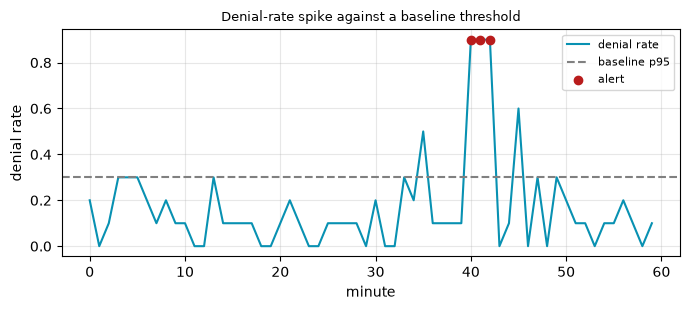

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(injected.minute, injected.denial_rate, color="#0891b2", label="denial rate")
ax.axhline(threshold, color="grey", linestyle="--", label="baseline p95")
ax.scatter(alerts.minute, alerts.denial_rate, color="#b91c1c", zorder=3, label="alert")
ax.set_xlabel("minute")
ax.set_ylabel("denial rate")
ax.set_title("Denial-rate spike against a baseline threshold", fontsize=9)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — a flat series with three points above the dashed line, marked. The chart is the artefact
that makes the alert reviewable in ten seconds.

### Step 6 — What the log proves

A short table of claims and their support. This is the discipline that keeps an incident report from overclaiming.

In [8]:
claims = pd.DataFrame(
    [
        {"claim": "principal X made N requests", "supported": "yes, if records are complete",
         "caveat": "absence of a record is not proof of absence"},
        {"claim": "a decision was made at time T", "supported": "yes, to clock accuracy",
         "caveat": "clock skew across hosts"},
        {"claim": "nobody edited the log", "supported": "no", "caveat": "hash chain detects edits, does not prevent them"},
        {"claim": "the model output was harmful", "supported": "only if outputs are logged",
         "caveat": "most services log metadata, not completions"},
    ]
)
claims

,claim,supported,caveat
0,principal X made N requests,"yes, if records are complete",absence of a record is not proof of absence
1,a decision was made at time T,"yes, to clock accuracy",clock skew across hosts
2,nobody edited the log,no,"hash chain detects edits, does not prevent them"
3,the model output was harmful,only if outputs are logged,"most services log metadata, not completions"


**Expected output** — four claims with honest support. The third row is the one most often misstated in audit
reports, and the fourth explains why incident reconstruction needs output sampling.

## Exercises

1. **Redact more.** Add a phone-number pattern and a token-shaped pattern (long base62 strings). Check for false
   positives on invoice numbers.
2. **Break the chain properly.** Delete a middle record without recomputing hashes, and confirm which index is
   reported. Then recompute the whole chain and explain why that is still detectable if the head hash is stored
   elsewhere.
3. **Tune the rule.** Change the absolute-count condition to 2 and count alerts outside the burst. What is the
   cost of that sensitivity?
4. **Add a second metric.** Track refusal rate per principal and design a rule that catches one user's unusual
   behaviour without flagging a global spike.

## Reflection questions

1. Why is a hash chain not a substitute for off-host log shipping?
2. Which fields would you drop from the schema to reduce personal data, and what investigation would that break?
3. If outputs are not logged, what can an incident report honestly say about what the model said?

## References

1. NIST, *SP 800-92*, Guide to Computer Security Log Management, 2006.
2. OWASP, *ASVS* 4.0.3, V7 (logging and monitoring).
3. NIST, *AI 600-1*, Generative AI Profile, 2024 — monitoring and incident response.
4. Kent, K. and Souppaya, M., *SP 800-92* — log integrity and retention.